# Inspecting raw data

Notebook purpose:
- Inspect missing information and data distributions
- Inspect characteristics of IPCEI firms and their collaborations

#### 1. Set-up

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

In [2]:
plt.style.use("default")
mpl.rcParams.update(mpl.rcParamsDefault)

Load paths and data

In [3]:
# paths
from ipcei_spillovers.io import data_path, results_path, load_df, save_df, save_fig
from ipcei_spillovers.plotting import (
    to_dt,
    to_month,
    style_ax,
    COLORS,
    PLOT_START,
    round_colors,
    parse_iso2_list,
    cross_border,
    monthly_rate,
    monthly_rate_column,
    classify_collaboration,
    cap_at_quantile,
    iso2_to_iso3,
    decade_shares
    )

In [4]:
# ============================================================
# Load data
# ============================================================

event_panel = load_df(
    "interim", "combined", "edge_event_stack_ipcei_jan26.csv", low_memory=False
)
firm_master_ipcei_events = load_df(
    "interim", "combined", "firm_master_ipcei_events_jan26.csv", low_memory=False
)
firm_master_ipcei = load_df(
    "interim", "combined", "firm_master_ipcei_jan26.csv", low_memory=False
)
partnership_master_ipcei = load_df(
    "interim", "combined", "partnership_master_ipcei_jan26.csv", low_memory=False
)

print(f"event_panel: {event_panel.shape}")
print(f"firm_master_ipcei: {firm_master_ipcei.shape}")
print(f"partnership_master_ipcei: {partnership_master_ipcei.shape}")
print(f"firm_master_ipcei_events: {firm_master_ipcei_events.shape}")

event_panel: (86597, 72)
firm_master_ipcei: (239782, 31)
partnership_master_ipcei: (3943633, 74)
firm_master_ipcei_events: (173, 36)


#### 2. Plot firm characteristics

Primary and operating countries

/Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/ipcei-spillovers/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


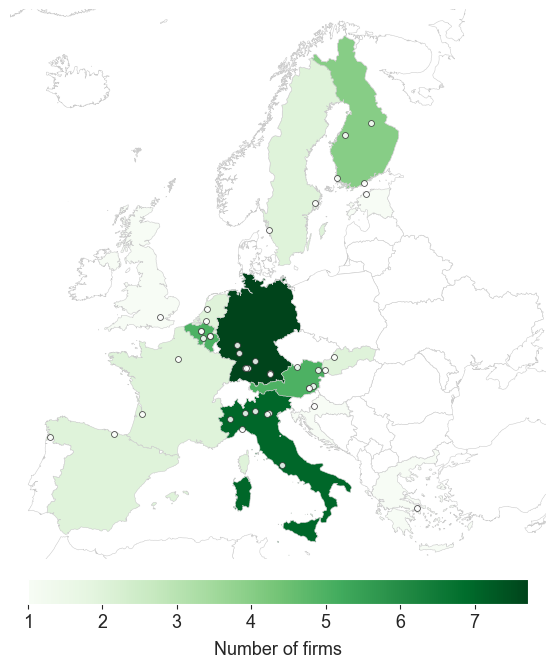

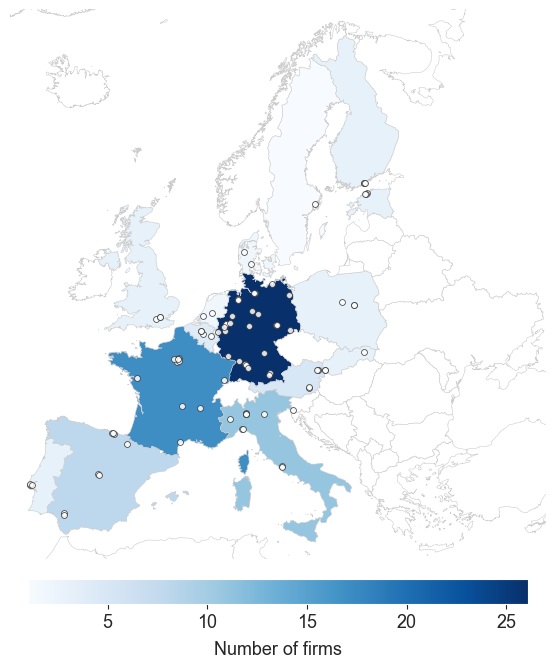

In [4]:
# ============================================================
# Map 1: Primary country of IPCEI firms — Battery vs Hydrogen
# ============================================================

import geopandas as gpd
import requests, zipfile, tempfile, os

# ── Load world geometries — 10m resolution for sharp borders ──────────────────
url = "https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip"
tmp = tempfile.mkdtemp()
zip_path = os.path.join(tmp, "world.zip")
with open(zip_path, "wb") as f:
    f.write(requests.get(url).content)
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(tmp)

world = gpd.read_file(os.path.join(tmp, "ne_10m_admin_0_countries.shp"))

# ── Patch known Natural Earth ISO issues ──────────────────────────────────────
iso_patches = {
    "France":    "FRA",
    "Norway":    "NOR",
    "Kosovo":    "XKX",
    "N. Cyprus": "CYP",
}
for name, iso3 in iso_patches.items():
    world.loc[world["NAME"].str.contains(name, na=False), "ADM0_A3"] = iso3

# ── Reproject to EPSG:3035 (EU flat projection) ───────────────────────────────
world = world.to_crs("EPSG:3035")

# ── Firm counts per technology ────────────────────────────────────────────────
fm = firm_master_ipcei.copy()
types_lc          = fm["ipcei_types"].astype("string").str.lower()
fm["is_battery"]  = types_lc.str.contains("battery",  na=False)
fm["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)

def country_counts(df, mask, iso2_col="primary_country"):
    return (
        df.loc[mask]
          .dropna(subset=[iso2_col])
          .assign(iso3=lambda d: d[iso2_col].apply(iso2_to_iso3))
          .dropna(subset=["iso3"])
          .groupby("iso3", as_index=False)
          .agg(n_firms=("Linkedin_name", "nunique"))
    )

battery_counts  = country_counts(fm, fm["is_battery"])
hydrogen_counts = country_counts(fm, fm["is_hydrogen"])

def make_world_merged(counts):
    cap = cap_at_quantile(counts["n_firms"], 0.98)
    return (
        world.merge(counts, left_on="ADM0_A3", right_on="iso3", how="left")
             .assign(n_firms_capped=lambda d: d["n_firms"].clip(upper=cap))
    )

world_battery  = make_world_merged(battery_counts)
world_hydrogen = make_world_merged(hydrogen_counts)

# ── Europe bounds in EPSG:3035 ────────────────────────────────────────────────
xlim = (2_500_000, 6_500_000)
ylim = (1_400_000, 5_500_000)

# ── Plot each map as a separate file ─────────────────────────────────────────
panels = [
    (world_battery,  "Greens", "Battery IPCEI firms",  "firms_battery_primarycountry_map"),
    (world_hydrogen, "Blues",  "Hydrogen IPCEI firms", "firms_hydrogen_primarycountry_map"),
]

for gdf, cmap, title, figname in panels:
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.set_facecolor("white")

    gdf.plot(
        column       = "n_firms_capped",
        ax           = ax,
        cmap         = cmap,
        linewidth    = 0.4,
        edgecolor    = "#cccccc",
        legend       = True,
        missing_kwds = {
            "color":     "white",
            "edgecolor": "#cccccc",
            "label":     "No IPCEI firms"
        },
        legend_kwds  = {
            #"label":       "Number of firms",
            "shrink":      0.65,
            "orientation": "horizontal",
            "pad":         0.03,
        },
    )

    cbar = ax.get_figure().axes[-1]
    cbar.tick_params(labelsize=13)
    cbar.set_xlabel("Number of firms", fontsize=13, labelpad=6)

    # ── HQ location dots ─────────────────────────────────────────────────────
    tech_mask = fm["is_battery"] if "battery" in figname else fm["is_hydrogen"]
    hq = fm.loc[tech_mask].dropna(subset=["primary_latitude", "primary_longitude"]).copy()

    hq_gdf = gpd.GeoDataFrame(
        hq,
        geometry=gpd.points_from_xy(
            hq["primary_latitude"],   # ← this is actually longitude
            hq["primary_longitude"]   # ← this is actually latitude
        ),
        crs="EPSG:4326"
    ).to_crs("EPSG:3035")

    hq_gdf.plot(
        ax         = ax,
        color      = "white",
        edgecolor  = "#333333",
        markersize = 18,
        linewidth  = 0.6,
        alpha      = 0.85,
        zorder     = 5
    )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.axis("off")
    #ax.set_title(title, fontsize=12, fontweight="bold", pad=8)

    plt.tight_layout()
    save_fig(fig, "descriptives_raw", figname)
    plt.show()

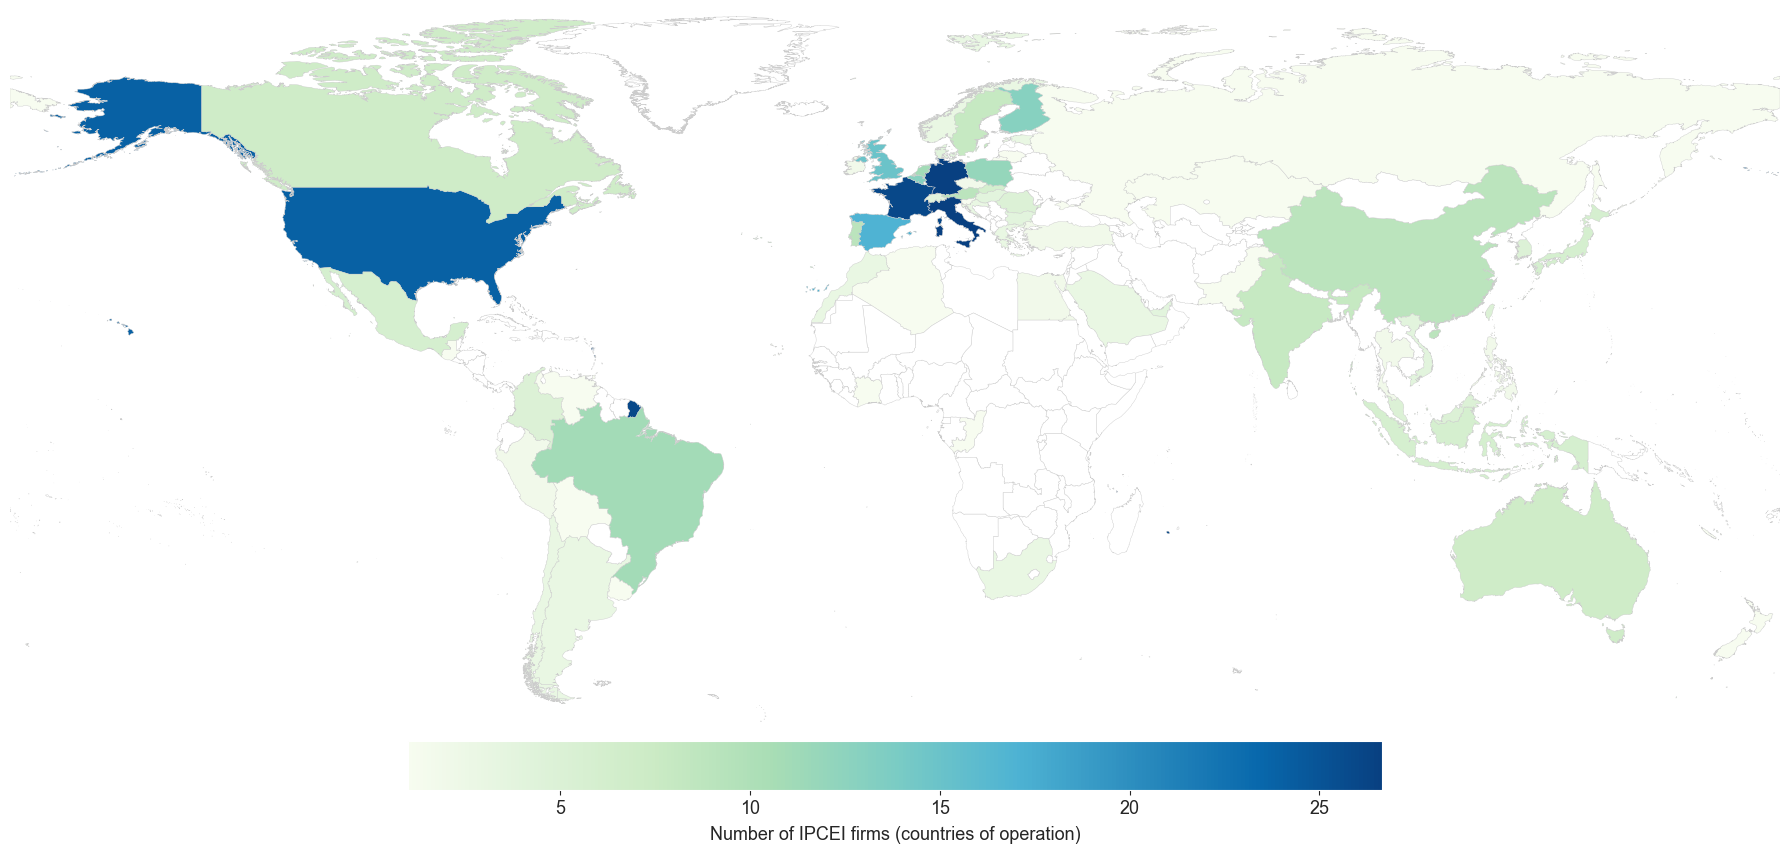

In [5]:
# ============================================================
# Map 2: Countries of operation — global, Battery + Hydrogen combined
# Single teal colorscale by total firm presence
# ============================================================

import geopandas as gpd
#import matplotlib.colors as mc
import requests, zipfile, tempfile, os

# ── Load 10m world geometries ─────────────────────────────────────────────────
url = "https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip"
tmp = tempfile.mkdtemp()
zip_path = os.path.join(tmp, "world.zip")
with open(zip_path, "wb") as f:
    f.write(requests.get(url).content)
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(tmp)

world_op = gpd.read_file(os.path.join(tmp, "ne_10m_admin_0_countries.shp"))

# ── Patch ISO issues ──────────────────────────────────────────────────────────
iso_patches = {
    "France":    "FRA",
    "Norway":    "NOR",
    "Kosovo":    "XKX",
    "N. Cyprus": "CYP",
}
for name, iso3 in iso_patches.items():
    world_op.loc[
        world_op["NAME"].str.contains(name, na=False), "ADM0_A3"
    ] = iso3

# ── Firm presence — all IPCEI combined ───────────────────────────────────────
fm = firm_master_ipcei.copy()

def explode_countries(df, mask=None, iso2_col="countries"):
    sub = df if mask is None else df.loc[mask]
    sub = sub[["Linkedin_name", iso2_col]].copy()
    if sub[iso2_col].dtype == object:
        sub[iso2_col] = sub[iso2_col].apply(
            lambda x: x if isinstance(x, list)
            else [c.strip() for c in str(x).split(",") if c.strip()]
            if pd.notna(x) else []
        )
    sub = sub.explode(iso2_col).rename(columns={iso2_col: "iso2"})
    sub["iso3"] = sub["iso2"].apply(iso2_to_iso3)
    return (
        sub.dropna(subset=["iso3"])
           .groupby("iso3", as_index=False)
           .agg(n_firms=("Linkedin_name", "nunique"))
    )

# All IPCEI firms combined
ipcei_mask = fm["treated_any"].fillna(0).astype(int) == 1
presence_counts = explode_countries(fm, ipcei_mask)

cap = cap_at_quantile(presence_counts["n_firms"], 0.98)
presence_counts["n_firms_capped"] = presence_counts["n_firms"].clip(upper=cap)

# ── Merge into world ──────────────────────────────────────────────────────────
world_op = world_op.merge(
    presence_counts[["iso3", "n_firms_capped"]],
    left_on="ADM0_A3", right_on="iso3", how="left"
).drop(columns=["iso3"], errors="ignore")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(18, 9))
ax.set_facecolor("white")

world_op.plot(
    column       = "n_firms_capped",
    ax           = ax,
    cmap         = "GnBu",
    linewidth    = 0.3,
    edgecolor    = "#cccccc",
    legend       = True,
    missing_kwds = {
        "color":     "white",
        "edgecolor": "#cccccc",
        "label":     "No IPCEI firm presence"
    },
    legend_kwds  = {
        #"label":       "Number of IPCEI firms (countries of operation)",
        "shrink":      0.55,
        "orientation": "horizontal",
        "pad":         0.02,
        #"anchor":      (0.0, 0.0),
    },
)

cbar = ax.get_figure().axes[-1]
cbar.tick_params(labelsize=13)
cbar.set_xlabel("Number of IPCEI firms (countries of operation)", fontsize=13, labelpad=6)

ax.set_xlim([-180, 180])
ax.set_ylim([-60, 85])
ax.axis("off")

plt.tight_layout()
save_fig(fig, "descriptives_raw", "firms_ipcei_countryoperations_map_global")
plt.show()

Firm type, age and size

IPCEI type counts (firms):
Hydrogen    108
Battery      47
Both          5
Neither       0


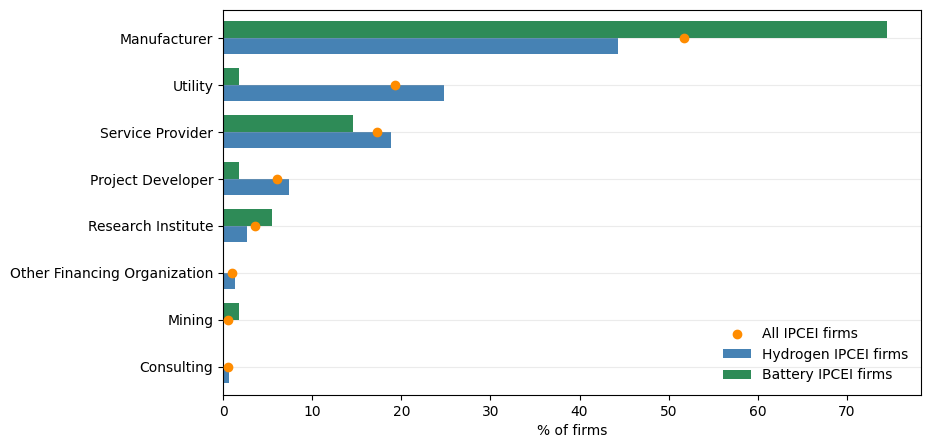

In [9]:
# ============================================================
# Firm type by IPCEI type (Hydrogen vs Battery) + overall dot
# ============================================================
fm = firm_master_ipcei.copy()

ipcei = (
    fm.loc[fm["treated_any"].fillna(0).astype(int) == 1,
           ["Linkedin_name", "firm_type", "ipcei_types"]]
      .dropna(subset=["firm_type", "ipcei_types"])
      .drop_duplicates("Linkedin_name")
      .copy()
)

# ------------------------------------------------------------
# Detect IPCEI type from ipcei_types (string field)
# ------------------------------------------------------------
types_lc = ipcei["ipcei_types"].astype("string").str.lower()

ipcei["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
ipcei["is_battery"]  = types_lc.str.contains("battery", na=False)

# (optional) sanity check
print("IPCEI type counts (firms):")
print(pd.Series({
    "Hydrogen": ipcei.loc[ipcei["is_hydrogen"], "Linkedin_name"].nunique(),
    "Battery":  ipcei.loc[ipcei["is_battery"], "Linkedin_name"].nunique(),
    "Both":     ipcei.loc[ipcei["is_hydrogen"] & ipcei["is_battery"], "Linkedin_name"].nunique(),
    "Neither":  ipcei.loc[~(ipcei["is_hydrogen"] | ipcei["is_battery"]), "Linkedin_name"].nunique(),
}).to_string())

# ------------------------------------------------------------
# Expand firm_type roles
# ------------------------------------------------------------
roles = (
    ipcei[["Linkedin_name", "firm_type", "is_hydrogen", "is_battery"]]
    .assign(role=lambda d: d["firm_type"].astype("string").str.split(","))
    .explode("role")
)
roles["role"] = roles["role"].astype("string").str.strip()

def role_share(df):
    return df["role"].value_counts(normalize=True).mul(100)

share_h2   = role_share(roles.loc[roles["is_hydrogen"]])
share_batt = role_share(roles.loc[roles["is_battery"]])
share_all  = role_share(roles)

plot_df = pd.DataFrame({
    "Hydrogen IPCEI firms": share_h2,
    "Battery IPCEI firms": share_batt,
    "All IPCEI firms": share_all
}).fillna(0)

# sort by overall prevalence (dot)
plot_df = plot_df.sort_values("All IPCEI firms")

# ------------------------------------------------------------
# Plot: bars + overall dot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))

plot_df[["Hydrogen IPCEI firms", "Battery IPCEI firms"]].plot(
    kind="barh",
    ax=ax,
    color=COLORS["two"],
    width=0.7
)

ypos = np.arange(len(plot_df))
ax.scatter(
    plot_df["All IPCEI firms"],
    ypos,
    color="darkorange",
    zorder=3,
    label="All IPCEI firms"
)

ax.set_xlabel("% of firms")
ax.set_ylabel("")
style_ax(ax)
ax.legend(frameon=False, loc="lower right")

save_fig(fig, "descriptives_raw", "firms_ipcei_firmtype_barchart")
plt.show()

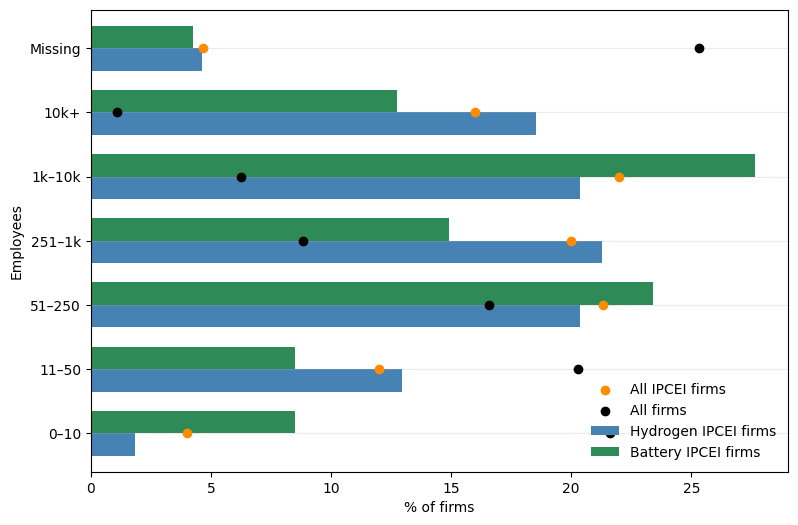

In [12]:
# ============================================================
# Staff count distribution by IPCEI type
# ============================================================
fm = firm_master_ipcei.copy()

# one row per firm
base = (
    fm.drop_duplicates("Linkedin_name")
      .copy()
)

# numeric staffCount
base["staffCount_num"] = pd.to_numeric(base["staffCount"], errors="coerce")

# IPCEI type flags
types_lc = base["ipcei_types"].astype("string").str.lower()
base["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
base["is_battery"]  = types_lc.str.contains("battery", na=False)

# ------------------------------------------------------------
# Staff count bins
# ------------------------------------------------------------
bins = [0, 10, 50, 250, 1000, 10000, np.inf]
labels = ["0–10", "11–50", "51–250", "251–1k", "1k–10k", "10k+"]

base["staff_bin"] = pd.cut(
    base["staffCount_num"],
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=True
)

# add Missing
base["staff_bin"] = base["staff_bin"].cat.add_categories(["Missing"]).fillna("Missing")

# ------------------------------------------------------------
# Shares
# ------------------------------------------------------------
def share(df):
    return df["staff_bin"].value_counts(normalize=True).mul(100)

treated = base.loc[base["treated_any"].fillna(0).astype(int) == 1]

share_h2   = share(treated.loc[treated["is_hydrogen"]])
share_batt = share(treated.loc[treated["is_battery"]])
share_ipcei = share(treated)
share_all   = share(base)

# align bins
order = labels + ["Missing"]
plot_df = pd.DataFrame({
    "Hydrogen IPCEI firms": share_h2,
    "Battery IPCEI firms":  share_batt,
    "All IPCEI firms":      share_ipcei,
    "All firms":      share_all,
}).reindex(order).fillna(0)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

# bars: Hydrogen & Battery
plot_df[["Hydrogen IPCEI firms", "Battery IPCEI firms"]].plot(
    kind="barh",
    ax=ax,
    color=COLORS["two"],
    width=0.7
)

ypos = np.arange(len(plot_df))

# dot: all IPCEI
ax.scatter(
    plot_df["All IPCEI firms"],
    ypos,
    color=COLORS["three"][2],  # orange
    zorder=3,
    label="All IPCEI firms"
)

# dot: all firms
ax.scatter(
    plot_df["All firms"],
    ypos,
    color="black",
    zorder=3,
    label="All firms"
)

ax.set_xlabel("% of firms")
ax.set_ylabel("Employees")
style_ax(ax)
ax.legend(frameon=False, loc="lower right")

save_fig(fig, "descriptives_raw", "firms_all_staffcount_barchart")
plt.show()

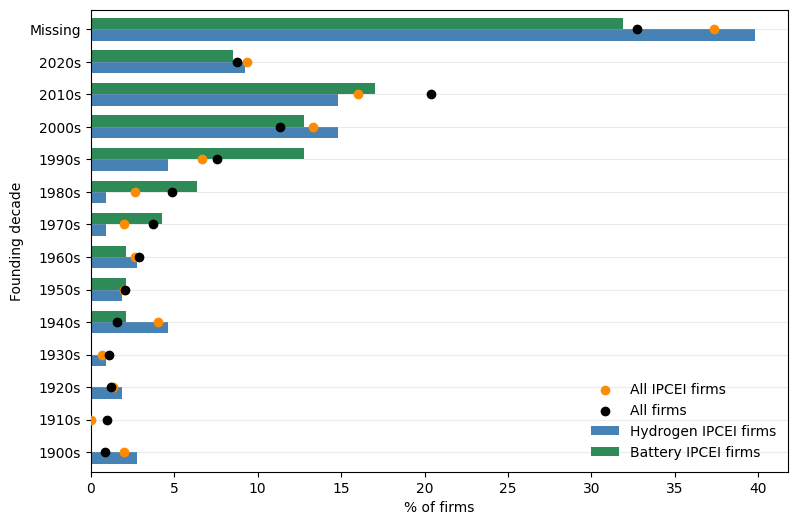

In [13]:
# ============================================================
# Founding decade distribution by IPCEI type
# ============================================================
fm = firm_master_ipcei.copy()

# one row per firm
base = (
    fm.drop_duplicates("Linkedin_name")
      .copy()
)

# IPCEI type flags
types_lc = base["ipcei_types"].astype("string").str.lower()
base["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
base["is_battery"]  = types_lc.str.contains("battery", na=False)

# ------------------------------------------------------------
# Shares by founding decade
# ------------------------------------------------------------
treated = base.loc[base["treated_any"].fillna(0).astype(int) == 1]

share_h2    = decade_shares(
    treated.loc[treated["is_hydrogen"]],
    start=1900, end=2031, step=10,
)
share_batt  = decade_shares(
    treated.loc[treated["is_battery"]],
    start=1900, end=2031, step=10,
)
share_ipcei = decade_shares(
    treated,
    start=1900, end=2031, step=10,
)
share_all   = decade_shares(
    base,
    start=1900, end=2031, step=10,
)

# align decades
plot_df = pd.DataFrame({
    "Hydrogen IPCEI firms": share_h2,
    "Battery IPCEI firms":  share_batt,
    "All IPCEI firms":      share_ipcei,
    "All firms":      share_all,
}).dropna(how="all")

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

# bars: Hydrogen & Battery
plot_df[["Hydrogen IPCEI firms", "Battery IPCEI firms"]].plot(
    kind="barh",
    ax=ax,
    color=COLORS["two"],
    width=0.7
)

ypos = np.arange(len(plot_df))

# dot: all IPCEI
ax.scatter(
    plot_df["All IPCEI firms"],
    ypos,
    color=COLORS["three"][2],  # orange
    zorder=3,
    label="All IPCEI firms"
)

# dot: all firms
ax.scatter(
    plot_df["All firms"],
    ypos,
    color="black",
    zorder=3,
    label="All firms"
)

ax.set_xlabel("% of firms")
ax.set_ylabel("Founding decade")
style_ax(ax)
ax.legend(frameon=False, loc="lower right")

save_fig(fig, "descriptives_raw", "firms_all_foundingdecade_barchart")
plt.show()

#### 4. Plot firm collaborations

Intensity

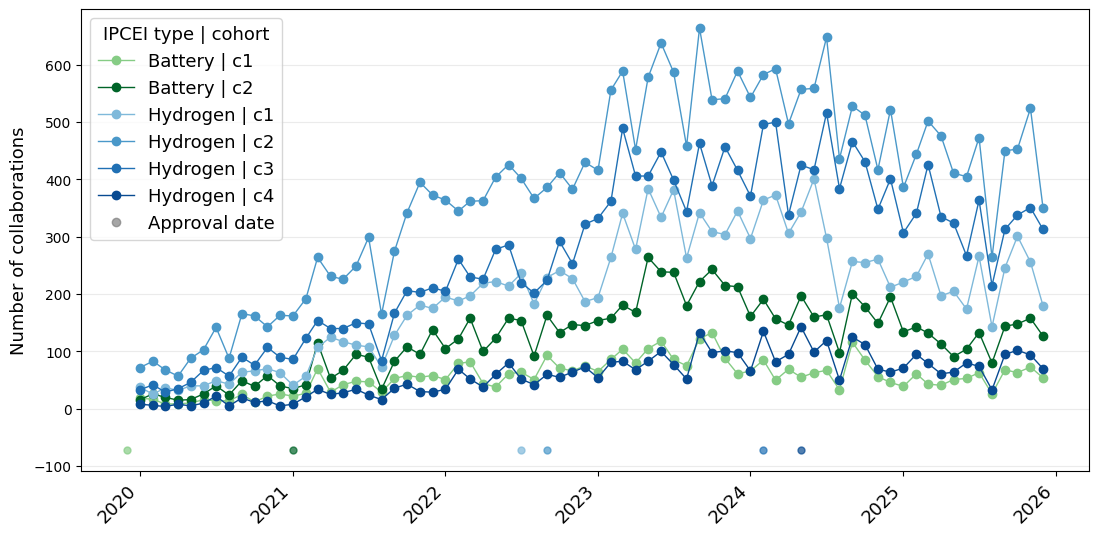

In [6]:
# ============================================================
# Collaboration intensity by cohort over time
# ============================================================

# ------------------------------------------------------------
# 0) Prep events: firm → cohort + event month
# ------------------------------------------------------------
ev = firm_master_ipcei_events.copy()

ev["ipcei_post_date"] = to_dt(ev["ipcei_post_date"])
ev = ev.dropna(subset=[
    "Linkedin_name", "ipcei_post_date", "ipcei_type", "ipcei_round"
]).copy()

ev["event_month"] = to_month(ev["ipcei_post_date"])
ev["cohort"] = (
    ev["ipcei_type"].astype("string").str.strip()
    + " | c"
    + ev["ipcei_round"].astype("string").str.strip()
)

# one rug point per month × cohort
ev_rug = ev.drop_duplicates(subset=["event_month", "cohort"]).copy()

# firm → cohort mapping (a firm can appear in multiple cohorts)
firm_to_cohorts = (
    ev[["Linkedin_name", "cohort"]]
    .drop_duplicates()
)

cohorts = sorted(firm_to_cohorts["cohort"].unique())

# ------------------------------------------------------------
# 1) Prep partnerships: add month + restrict window
# ------------------------------------------------------------
p = partnership_master_ipcei.copy()

p["post_date"] = to_dt(p["post_date"])
p = p.loc[p["post_date"].ge(PLOT_START)].copy()
p["month"] = to_month(p["post_date"])

for c in ["source", "target", "collaboration_id"]:
    if c not in p.columns:
        raise KeyError(f"Missing required column: {c}")

# ------------------------------------------------------------
# 2) Expand partnerships to cohort exposure
# ------------------------------------------------------------
src = firm_to_cohorts.rename(
    columns={"Linkedin_name": "source", "cohort": "cohort"}
)
tgt = firm_to_cohorts.rename(
    columns={"Linkedin_name": "target", "cohort": "cohort"}
)

p_src = p.merge(src, on="source", how="left")
p_tgt = p.merge(tgt, on="target", how="left")

p_long = pd.concat(
    [
        p_src[["month", "collaboration_id", "cohort"]],
        p_tgt[["month", "collaboration_id", "cohort"]],
    ],
    ignore_index=True
)

# drop non-exposed & avoid double counting
p_long = (
    p_long
    .dropna(subset=["cohort"])
    .drop_duplicates(subset=["month", "collaboration_id", "cohort"])
)

monthly_by_cohort = (
    p_long.groupby(["cohort", "month"])["collaboration_id"]
          .nunique()
          .reset_index(name="n_collabs")
)

# ------------------------------------------------------------
# 3) Colors (unchanged logic: Blues = H2, Greens = Battery)
# ------------------------------------------------------------
battery_cohorts  = [c for c in cohorts if c.lower().startswith("battery")]
hydrogen_cohorts = [c for c in cohorts if c.lower().startswith("hydrogen")]

color_map = {}
color_map.update(round_colors("battery",  battery_cohorts))
color_map.update(round_colors("hydrogen", hydrogen_cohorts))

# ------------------------------------------------------------
# 4) Plot: cohort lines + cohort rug
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 6))

# lines
for c in cohorts:
    sub = (
        monthly_by_cohort
        .loc[monthly_by_cohort["cohort"] == c]
        .sort_values("month")
    )
    ax.plot(
        sub["month"],
        sub["n_collabs"],
        marker="o",
        linewidth=1,
        color=color_map.get(c),
        label=c.capitalize(),
    )

# rug (event timing)
ymin, ymax = ax.get_ylim()
rug_y = ymin - 0.06 * (ymax - ymin)

for c in cohorts:
    sub = ev_rug.loc[ev_rug["cohort"] == c]
    if len(sub) == 0:
        continue
    ax.scatter(
        sub["event_month"],
        [rug_y] * len(sub),
        s=25,
        alpha=0.7,
        color=color_map.get(c),
    )

ax.set_ylim(rug_y - 0.05 * (ymax - ymin), ymax)

#ax.set_xlabel("Year")
ax.set_ylabel("Number of collaborations", fontsize=13)
style_ax(ax)
plt.xticks(rotation=45, ha="right", fontsize=13)

# Build legend handles: cohort lines + one generic rug entry
from matplotlib.lines import Line2D
handles, labels = ax.get_legend_handles_labels()
rug_handle = Line2D(
    [0], [0],
    marker="o",
    linestyle="None",
    color="grey",
    markersize=6,
    alpha=0.7,
    label="Approval date",
)

handles = handles + [rug_handle]
labels = labels + ["Approval date"]

# legend cap
MAX_LEGEND = 12
if len(labels) > MAX_LEGEND + 1:  # +1 for the rug entry
    ax.legend(
        handles[:MAX_LEGEND] + [handles[-1]],
        labels[:MAX_LEGEND] + [f"+{len(labels) - MAX_LEGEND - 1} more"] + [labels[-1]],
        title="IPCEI type | cohort",
        loc="upper left",
        fontsize=13,
        title_fontsize=13,
        frameon=True,
    )
else:
    ax.legend(
        handles, labels,
        title="IPCEI type | cohort",
        loc="upper left",
        fontsize=13,
        title_fontsize=13,
        frameon=True,
    )

save_fig(fig, "descriptives_raw", "collaborations_ipcei_intensity_lineplot")
plt.show()

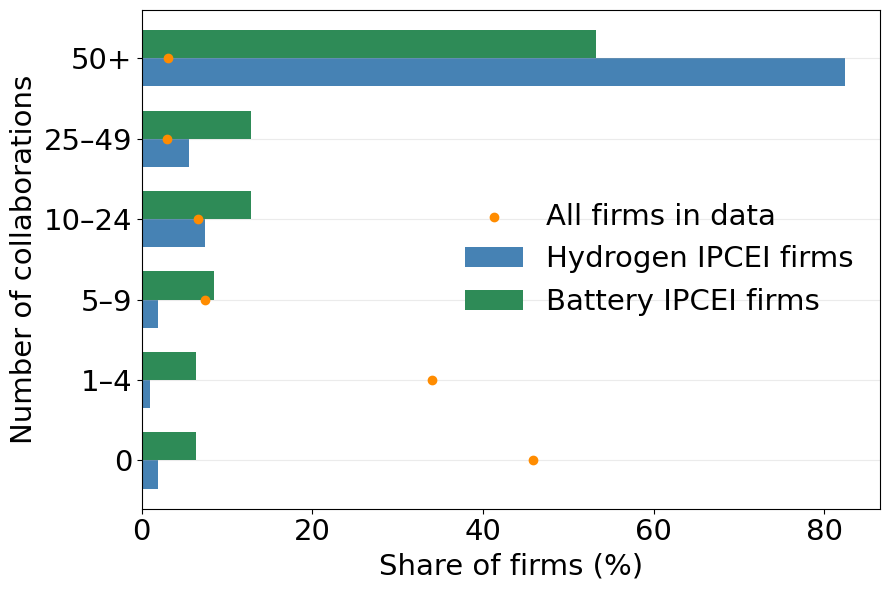

In [11]:
# ============================================================
# Collaboration intensity distribution by IPCEI type
# ============================================================

fm = firm_master_ipcei.copy()
p = partnership_master_ipcei.copy()

# one row per firm
base = fm.drop_duplicates("Linkedin_name").copy()

# ------------------------------------------------------------
# 1) Compute unique collaboration counts per firm
# ------------------------------------------------------------

collabs = p[["source", "target", "collaboration_id"]].copy()

long = pd.concat([
    collabs.rename(columns={"source": "Linkedin_name"})[["Linkedin_name", "collaboration_id"]],
    collabs.rename(columns={"target": "Linkedin_name"})[["Linkedin_name", "collaboration_id"]],
], ignore_index=True)

firm_counts = (
    long.groupby("Linkedin_name")["collaboration_id"]
        .nunique()
        .reset_index(name="n_collabs")
)

base = base.merge(firm_counts, on="Linkedin_name", how="left")
base["n_collabs"] = base["n_collabs"].fillna(0).astype(int)

# ------------------------------------------------------------
# 2) IPCEI type flags
# ------------------------------------------------------------

types_lc = base["ipcei_types"].astype("string").str.lower()
base["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
base["is_battery"]  = types_lc.str.contains("battery",  na=False)

# ------------------------------------------------------------
# 3) Collaboration buckets
# ------------------------------------------------------------

bins   = [0, 1, 5, 10, 25, 50, np.inf]
labels = ["0", "1–4", "5–9", "10–24", "25–49", "50+"]

base["collab_bin"] = pd.cut(
    base["n_collabs"],
    bins=bins,
    labels=labels,
    right=False,
)

# ------------------------------------------------------------
# 4) Shares
# ------------------------------------------------------------

def share(df):
    return df["collab_bin"].value_counts(normalize=True).mul(100)

treated = base.loc[base["treated_any"].fillna(0).astype(int) == 1]

share_h2    = share(treated.loc[treated["is_hydrogen"]])
share_batt  = share(treated.loc[treated["is_battery"]])
share_ipcei = share(treated)
share_all   = share(base)

# align bins
plot_df = pd.DataFrame({
    "Hydrogen IPCEI firms": share_h2,
    "Battery IPCEI firms":  share_batt,
    "All firms":      share_all,
}).reindex(labels).fillna(0)

# ------------------------------------------------------------
# 5) Plot
# ------------------------------------------------------------

# ── Font sizes ────────────────────────────────────────────────────────────────
AXIS_LABEL_FS = 21
TICK_FS = 21
LEGEND_FS = 21

fig, ax = plt.subplots(figsize=(9, 6))

# bars: Hydrogen & Battery
plot_df[["Hydrogen IPCEI firms", "Battery IPCEI firms"]].plot(
    kind="barh",
    ax=ax,
    color=COLORS["two"],
    width=0.7,
)

ypos = np.arange(len(plot_df))

# dot: all firms
ax.scatter(
    plot_df["All firms"],
    ypos,
    color="darkorange",
    zorder=3,
    label="All firms in data",
)

ax.set_xlabel("Share of firms (%)", fontsize=AXIS_LABEL_FS)
ax.set_ylabel("Number of collaborations", fontsize=AXIS_LABEL_FS)
ax.tick_params(axis="both", labelsize=TICK_FS)
style_ax(ax)
ax.legend(frameon=False, loc="center right", fontsize=LEGEND_FS)

plt.tight_layout()
save_fig(fig, "descriptives_raw", "collaborations_all_distribution_barchart")
plt.show()

Intensity around event time

In [1]:
# ============================================================
# Top 10 most collaborative IPCEI firms by technology
# ============================================================

from pathlib import Path

top_n = 10

# Top 10 battery — exclude pre-panel firms
top_battery = (
    base.loc[
        base["treated_any"].fillna(0).astype(int).eq(1) &
        base["is_battery"] &
        (pd.to_datetime(base["first_battery_date"], errors="coerce") >= pd.Timestamp("2020-01-01")),
        ["Linkedin_name", "primary_country", "n_collabs"]
    ]
    .sort_values(["n_collabs", "Linkedin_name"], ascending=[False, True])
    .head(top_n)
    .reset_index(drop=True)
)

top_battery.insert(0, "rank", range(1, len(top_battery) + 1))

# Top 10 hydrogen — exclude pre-panel firms
top_hydrogen = (
    base.loc[
        base["treated_any"].fillna(0).astype(int).eq(1) &
        base["is_hydrogen"] &
        (pd.to_datetime(base["first_hydrogen_date"], errors="coerce") >= pd.Timestamp("2020-01-01")),
        ["Linkedin_name", "primary_country", "n_collabs"]
    ]
    .sort_values(["n_collabs", "Linkedin_name"], ascending=[False, True])
    .head(top_n)
    .reset_index(drop=True)
)

top_hydrogen.insert(0, "rank", range(1, len(top_hydrogen) + 1))

# Save CSVs
battery_csv = results_path("tables", "main", "top10_battery_ipcei_firms.csv")
hydrogen_csv = results_path("tables", "main", "top10_hydrogen_ipcei_firms.csv")

battery_csv.parent.mkdir(parents=True, exist_ok=True)
top_battery.to_csv(battery_csv, index=False)
top_hydrogen.to_csv(hydrogen_csv, index=False)

print(f"Saved: {battery_csv}")
print(f"Saved: {hydrogen_csv}")

NameError: name 'base' is not defined

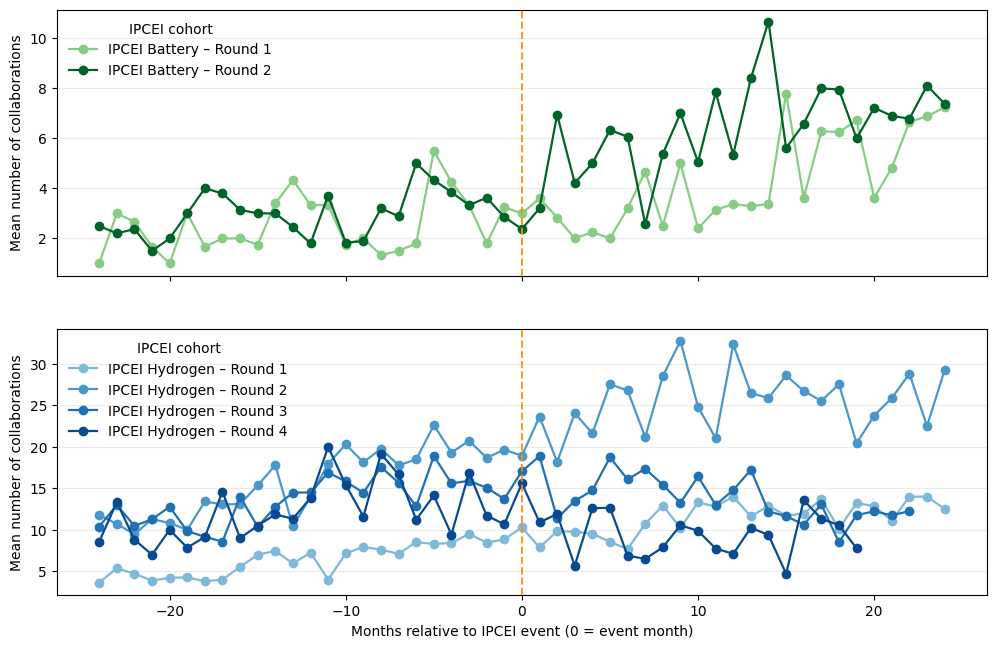

In [16]:
# ============================================================
# Collaboration dynamics around IPCEI events (by cohort)
# Not normalized – mean collaborations per event
# ============================================================

WINDOW = 24

# ------------------------------------------------------------
# 1) Restrict to symmetric event window
# ------------------------------------------------------------
ees = event_panel.copy()
ees = ees.loc[ees["event_time"].between(-WINDOW, WINDOW)].copy()

assert ees["event_id"].nunique() > 1, "Only one event detected — something is wrong."

# ------------------------------------------------------------
# 2) Count collaborations per event × event_time
# ------------------------------------------------------------
event_time_counts = (
    ees.groupby(
        ["event_id", "ipcei_type", "ipcei_round", "event_time"],
        as_index=False
    )["collaboration_id"]
    .nunique()
    .rename(columns={"collaboration_id": "n_collabs"})
)

# ------------------------------------------------------------
# 3) Average across events (cohort × event_time)
# ------------------------------------------------------------
g = (
    event_time_counts
    .groupby(
        ["ipcei_type", "ipcei_round", "event_time"],
        as_index=False
    )["n_collabs"]
    .mean()
)

# ------------------------------------------------------------
# 4) Plot by technology (Hydrogen / Battery)
# ------------------------------------------------------------
types = sorted(
    g["ipcei_type"].dropna().unique(),
    key=lambda x: str(x).lower()
)

fig, axes = plt.subplots(
    len(types),
    1,
    figsize=(12, 3.8 * len(types)),
    sharex=True
)

if len(types) == 1:
    axes = [axes]

for ax, t in zip(axes, types):
    sub = g[g["ipcei_type"] == t].copy()
    rounds = sorted(sub["ipcei_round"].dropna().unique())

    # round-specific shades (Greens for battery, Blues for hydrogen)
    colors = round_colors(t, rounds)

    for r in rounds:
        sr = (
            sub[sub["ipcei_round"] == r]
            .sort_values("event_time")
        )

        ax.plot(
            sr["event_time"],
            sr["n_collabs"],
            marker="o",
            linewidth=1.6,
            color=colors[r],
            label=f"IPCEI {t.capitalize()} – Round {int(r)}",
        )

    # event time
    ax.axvline(0, linestyle="--", linewidth=1.4, color="darkorange", alpha=0.9)

    ax.set_ylabel("Mean number of collaborations")
    style_ax(ax)
    ax.legend(title="IPCEI cohort", frameon=False)

axes[-1].set_xlabel("Months relative to IPCEI event (0 = event month)")

save_fig(
    fig,
    "descriptives_raw",
    "collaborations_ipcei_eventintensity_lineplot"
)

plt.show()

Cross-border

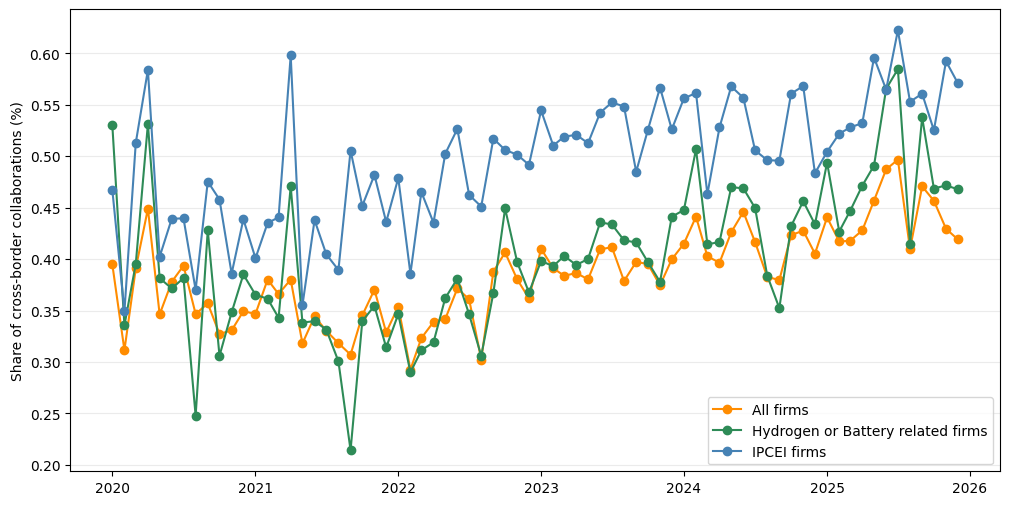

In [20]:
# ============================================================
# Cross-border collaboration share over time
# ============================================================

p = partnership_master_ipcei.copy()
fm = firm_master_ipcei.copy()

# dates
p["post_date"] = to_dt(p["post_date"])
p = p.dropna(subset=["post_date"]).copy()
p["month"] = to_month(p["post_date"])

# firm → country set
for c in ["countries", "primary_country", "hq_country"]:
    if c in fm.columns:
        country_col = c
        break
else:
    raise KeyError("No country column found in firm_master_ipcei")

firm_country = (
    fm[["Linkedin_name", country_col]]
    .drop_duplicates("Linkedin_name")
    .copy()
)
firm_country["country_set"] = firm_country[country_col].apply(parse_iso2_list)
country_map = dict(zip(firm_country["Linkedin_name"], firm_country["country_set"]))

# attach endpoint country sets
p["source_country_set"] = p["source"].map(country_map).apply(
    lambda x: x if isinstance(x, set) else set()
)
p["target_country_set"] = p["target"].map(country_map).apply(
    lambda x: x if isinstance(x, set) else set()
)

p["cross_border"] = [
    cross_border(a, b)
    for a, b in zip(p["source_country_set"], p["target_country_set"])
]

# masks
mask_all = pd.Series(True, index=p.index)

mask_energy = pd.Series(False, index=p.index)
for tech in ["Hydrogen", "Battery"]:
    if tech in p.columns:
        mask_energy |= pd.to_numeric(p[tech], errors="coerce").fillna(0).eq(1)

mask_ipcei = (
    pd.to_numeric(p["any_treated"], errors="coerce").fillna(0).eq(1)
    if "any_treated" in p.columns
    else pd.Series(False, index=p.index)
)

series = pd.concat(
    [
        monthly_rate(p, mask_ipcei,  "IPCEI firms"),
        monthly_rate(p, mask_energy, "Hydrogen or Battery related firms"),
        monthly_rate(p, mask_all,    "All firms"),
    ],
    ignore_index=True,
).loc[lambda d: d["month"] >= PLOT_START]

# plot
fig, ax = plt.subplots(figsize=(12, 6))

COLOR_MAP = {
    "IPCEI firms": "steelblue",
    "Hydrogen or Battery related firms": "seagreen",
    "All firms": "darkorange",
}

for name, sub in series.groupby("series"):
    sub = sub.sort_values("month")
    ax.plot(
        sub["month"],
        sub["rate"],
        marker="o",
        linewidth=1.5,
        color=COLOR_MAP[name],
        label=name,
    )

ax.set_ylabel("Share of cross-border collaborations (%)")
#ax.set_xlabel("Year")
style_ax(ax)
ax.legend()

save_fig(fig, "descriptives_raw", "collaborations_all_crossborder_lineplot")
plt.show()

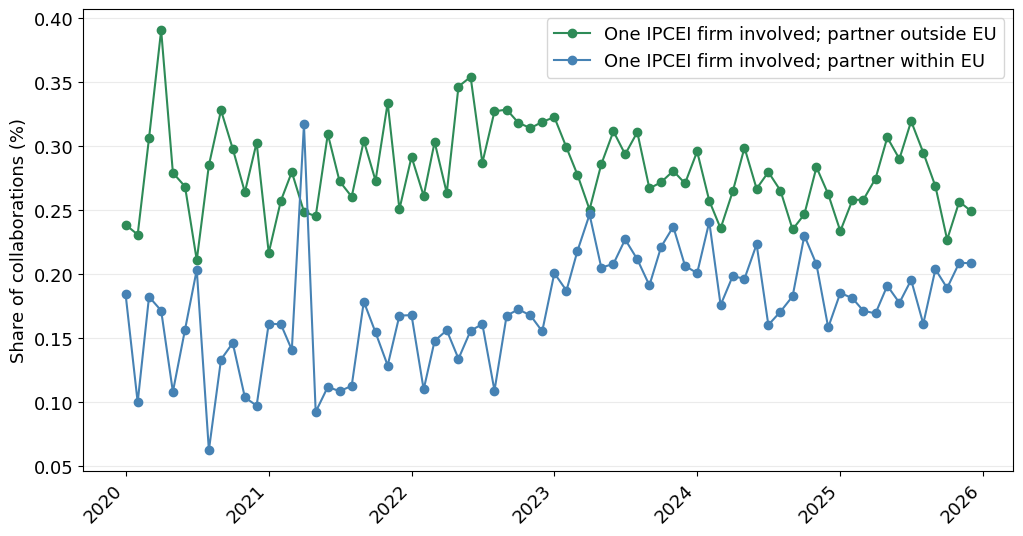

In [10]:
# ============================================================
# EU-internal vs non-EU collaborations
# ============================================================

p = partnership_master_ipcei.copy()
fm = firm_master_ipcei.copy()

# dates
p["post_date"] = to_dt(p["post_date"])
p = p.dropna(subset=["post_date"]).copy()
p["month"] = to_month(p["post_date"])

# firm → country set
for c in ["countries", "primary_country", "hq_country"]:
    if c in fm.columns:
        country_col = c
        break
else:
    raise KeyError("No country column found in firm_master_ipcei")

firm_country = (
    fm[["Linkedin_name", country_col]]
    .drop_duplicates("Linkedin_name")
    .copy()
)
firm_country["country_set"] = firm_country[country_col].apply(parse_iso2_list)
country_map = dict(zip(firm_country["Linkedin_name"], firm_country["country_set"]))

# attach endpoint country sets
p["source_country_set"] = p["source"].map(country_map).apply(
    lambda x: x if isinstance(x, set) else set()
)
p["target_country_set"] = p["target"].map(country_map).apply(
    lambda x: x if isinstance(x, set) else set()
)

# Filter to IPCEI collaborations
mask_ipcei = (
    pd.to_numeric(p["any_treated"], errors="coerce").fillna(0).eq(1)
    if "any_treated" in p.columns
    else pd.Series(False, index=p.index)
)

p_ipcei = p[mask_ipcei].copy()

# Classify each collaboration
p_ipcei["collab_type"] = [
    classify_collaboration(a, b)
    for a, b in zip(p_ipcei["source_country_set"], p_ipcei["target_country_set"])
]

# Create binary indicators for each type
p_ipcei["is_eu_internal"] = (p_ipcei["collab_type"] == "eu_internal").astype(float)
p_ipcei["is_non_eu"] = (p_ipcei["collab_type"] == "non_eu").astype(float)

series = pd.concat(
    [
        monthly_rate_column(p_ipcei, "is_eu_internal", "One IPCEI firm involved; partner within EU"),
        monthly_rate_column(p_ipcei, "is_non_eu", "One IPCEI firm involved; partner outside EU"),
    ],
    ignore_index=True,
).loc[lambda d: d["month"] >= PLOT_START]

# Plot
fig, ax = plt.subplots(figsize=(12, 6))

COLOR_MAP = {
    "One IPCEI firm involved; partner within EU": COLORS["two"][0],
    "One IPCEI firm involved; partner outside EU": COLORS["two"][1],
}

for name, sub in series.groupby("series"):
    sub = sub.sort_values("month")
    ax.plot(
        sub["month"],
        sub["rate"],
        marker="o",
        linewidth=1.5,
        color=COLOR_MAP[name],
        label=name,
    )

ax.set_ylabel("Share of collaborations (%)", fontsize=13)
style_ax(ax)

ax.tick_params(axis="both", labelsize=13)
plt.xticks(rotation=45, ha="right")

ax.legend(fontsize=13, title_fontsize=13)

save_fig(fig, "descriptives_raw", "collaborations_ipcei_crossborder_eu_lineplot")
plt.show()

Collab types

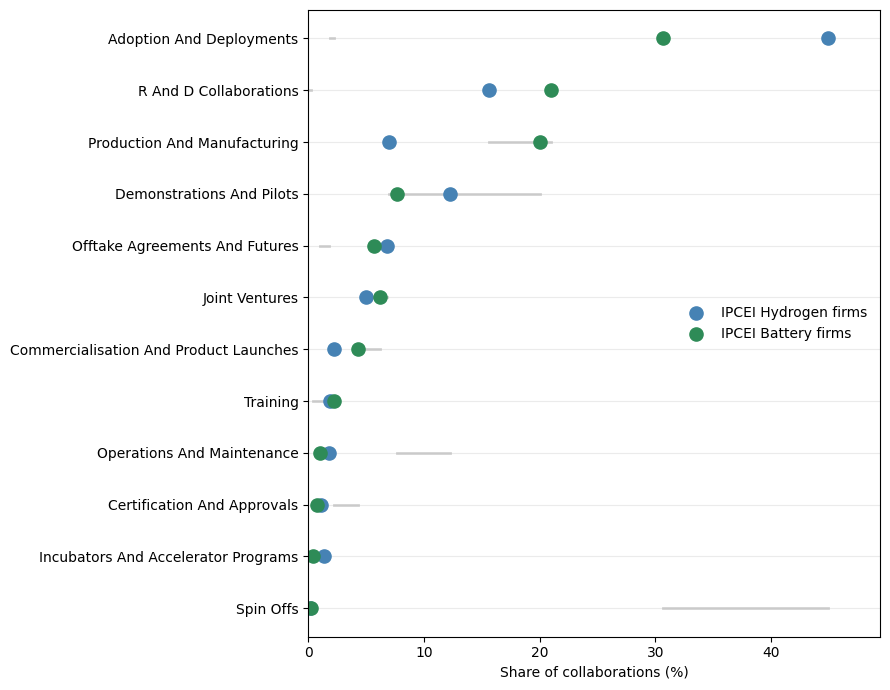

In [27]:
# ============================================================
# Collaboration activities: Activity stages & partnership forms
# ============================================================

fm = firm_master_ipcei.copy()
p = partnership_master_ipcei.copy()

activity_cols = [
    'r_and_d_collaborations',
    'demonstrations_and_pilots',
    'commercialisation_and_product_launches',
    'production_and_manufacturing',
    'offtake_agreements_and_futures',
    'adoption_and_deployments',
    'operations_and_maintenance',
]

partnership_cols = [
    'spin_offs',
    'joint_ventures',
    'incubators_and_accelerator_programs',
    'certification_and_approvals',
    'training',
]

collab_type_cols = [c for c in activity_cols + partnership_cols if c in p.columns]

# IPCEI firms
ipcei_firms = fm.loc[
    fm["treated_any"].fillna(0).astype(int) == 1,
    ["Linkedin_name", "ipcei_types"]
].dropna(subset=["Linkedin_name"]).drop_duplicates("Linkedin_name")

ipcei_firms["ipcei_type_group"] = (
    ipcei_firms["ipcei_types"].astype("string").str.lower().fillna("")
    .apply(lambda s: "Battery" if ("battery" in s and "hydrogen" not in s)
           else ("Hydrogen" if ("hydrogen" in s and "battery" not in s)
                 else "Other"))
)

tmp = p.copy()
for col in collab_type_cols:
    tmp[col] = pd.to_numeric(tmp[col], errors="coerce").fillna(0).astype(int)

src = tmp.rename(columns={"source": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id"] + collab_type_cols
]
tgt = tmp.rename(columns={"target": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id"] + collab_type_cols
]

endp = pd.concat([src, tgt], ignore_index=True).dropna(subset=["Linkedin_name"])

endp_ipcei = endp.merge(
    ipcei_firms[["Linkedin_name", "ipcei_type_group"]],
    on="Linkedin_name",
    how="inner"
)

records = []

for t in ["Hydrogen", "Battery"]:
    sub = endp_ipcei[endp_ipcei["ipcei_type_group"] == t]
    for c in collab_type_cols:
        n = sub.loc[sub[c] == 1, "collaboration_id"].nunique()
        records.append({"ipcei_type": t, "category": c, "n": n})

df = pd.DataFrame(records)

df["share"] = df.groupby("ipcei_type")["n"].transform(lambda x: 100 * x / x.sum())

pivot = df.pivot(index="category", columns="ipcei_type", values="share").reset_index()

pivot["avg"] = pivot[["Hydrogen", "Battery"]].mean(axis=1)
pivot = pivot.sort_values("avg")

# --- Cleveland plot ---
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(pivot))

for i, row in pivot.iterrows():
    ax.plot(
        [row["Hydrogen"], row["Battery"]],
        [y[i], y[i]],
        color="lightgray",
        linewidth=2,
        zorder=1
    )

ax.scatter(pivot["Hydrogen"], y,
           color=COLORS["three"][0], s=90, label="IPCEI Hydrogen firms", zorder=2)

ax.scatter(pivot["Battery"], y,
           color=COLORS["three"][1], s=90, label="IPCEI Battery firms", zorder=2)

ax.set_yticks(y)
ax.set_yticklabels(pivot["category"].str.replace("_", " ").str.title())

ax.set_xlabel("Share of collaborations (%)")
ax.set_xlim(0, pivot[["Hydrogen", "Battery"]].max().max() * 1.1)

style_ax(ax)
ax.legend(loc="center right", frameon=False)

plt.tight_layout()
save_fig(fig, "descriptives_raw", "collaborations_ipcei_activitytype_clevelandplot")
plt.show()

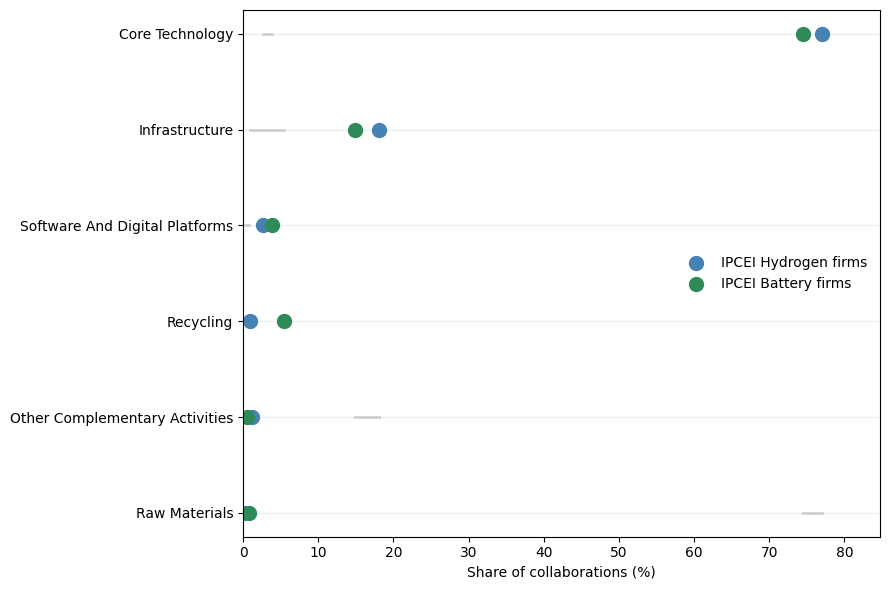

In [28]:
# ============================================================
# Value chain focus — Cleveland plot
# ============================================================

fm = firm_master_ipcei.copy()
p = partnership_master_ipcei.copy()

value_chain_cols = [
    'core_technology',
    'infrastructure',
    'software_and_digital_platforms',
    'raw_materials',
    'recycling',
    'other_complementary_activities',
]

value_chain_cols = [c for c in value_chain_cols if c in p.columns]

ipcei_firms = fm.loc[
    fm["treated_any"].fillna(0).astype(int) == 1,
    ["Linkedin_name", "ipcei_types"]
].dropna(subset=["Linkedin_name"]).drop_duplicates("Linkedin_name")

ipcei_firms["ipcei_type_group"] = (
    ipcei_firms["ipcei_types"].astype("string").str.lower().fillna("")
    .apply(lambda s: "Battery" if ("battery" in s and "hydrogen" not in s)
           else ("Hydrogen" if ("hydrogen" in s and "battery" not in s)
                 else "Other"))
)

tmp = p.copy()
for col in value_chain_cols:
    tmp[col] = pd.to_numeric(tmp[col], errors="coerce").fillna(0).astype(int)

src = tmp.rename(columns={"source": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id"] + value_chain_cols
]
tgt = tmp.rename(columns={"target": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id"] + value_chain_cols
]

endp = pd.concat([src, tgt], ignore_index=True).dropna(subset=["Linkedin_name"])

endp_ipcei = endp.merge(
    ipcei_firms[["Linkedin_name", "ipcei_type_group"]],
    on="Linkedin_name",
    how="inner"
)

records = []

for t in ["Hydrogen", "Battery"]:
    sub = endp_ipcei[endp_ipcei["ipcei_type_group"] == t]
    for c in value_chain_cols:
        n = sub.loc[sub[c] == 1, "collaboration_id"].nunique()
        records.append({"ipcei_type": t, "category": c, "n": n})

df = pd.DataFrame(records)

df["share"] = df.groupby("ipcei_type")["n"].transform(lambda x: 100 * x / x.sum())

pivot = df.pivot(index="category", columns="ipcei_type", values="share").reset_index()

pivot["avg"] = pivot[["Hydrogen", "Battery"]].mean(axis=1)
pivot = pivot.sort_values("avg")

# --- Cleveland plot ---
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(pivot))

for i, row in pivot.iterrows():
    ax.plot(
        [row["Hydrogen"], row["Battery"]],
        [y[i], y[i]],
        color="lightgray",
        linewidth=2,
        zorder=1
    )

ax.scatter(pivot["Hydrogen"], y,
           color=COLORS["three"][0], s=100, label="IPCEI Hydrogen firms", zorder=2)

ax.scatter(pivot["Battery"], y,
           color=COLORS["three"][1], s=100, label="IPCEI Battery firms", zorder=2)

ax.set_yticks(y)
ax.set_yticklabels(pivot["category"].str.replace("_", " ").str.title())

ax.set_xlabel("Share of collaborations (%)")
ax.set_xlim(0, pivot[["Hydrogen", "Battery"]].max().max() * 1.1)

style_ax(ax)
ax.legend(loc="center right", frameon=False)

plt.tight_layout()
save_fig(fig, "descriptives_raw", "collaborations_ipcei_valuechain_clevelandplot")
plt.show()
